In [18]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [19]:
PROJECT_DIR = r"D:\CSE Code\CSE465 Project"
MODEL_PATH = os.path.join(PROJECT_DIR, "model", "banknote_classifier.h5")
# Use Dataset/test for final evaluation
TEST_DIR = os.path.join(PROJECT_DIR, "Dataset", "test")
IMG_SIZE = 224

print("Loading model...")
model = keras.models.load_model(MODEL_PATH)
print("Model loaded successfully!")
print(f"Using test directory: {TEST_DIR}\n")


Loading model...


Model loaded successfully!
Using test directory: D:\CSE Code\CSE465 Project\Dataset\test



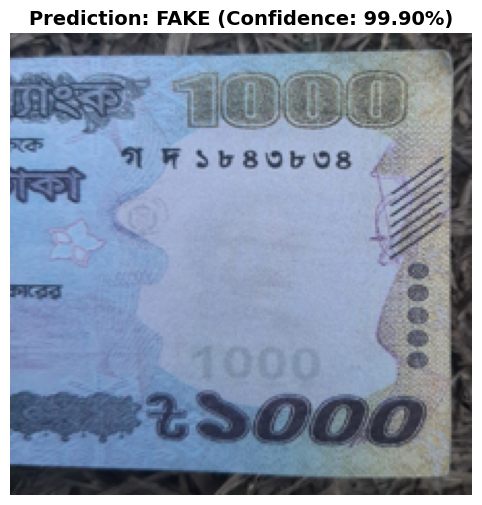

Result: FAKE
Confidence: 99.90%


In [20]:
def predict_single_image(image_path):
    """Predict single image"""
    img = Image.open(image_path)
    img = img.convert('RGB')
    img = img.resize((IMG_SIZE, IMG_SIZE))
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    prediction = model.predict(img_array, verbose=0)[0][0]
    
    if prediction < 0.5:
        result = "FAKE"
        confidence = (1 - prediction) * 100
    else:
        result = "REAL"
        confidence = prediction * 100
    
    return result, confidence, img

# Test a sample image
sample_image = os.path.join(TEST_DIR, "fake", os.listdir(os.path.join(TEST_DIR, "fake"))[0])
result, confidence, img = predict_single_image(sample_image)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title(f"Prediction: {result} (Confidence: {confidence:.2f}%)", 
          fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

print(f"Result: {result}")
print(f"Confidence: {confidence:.2f}%")

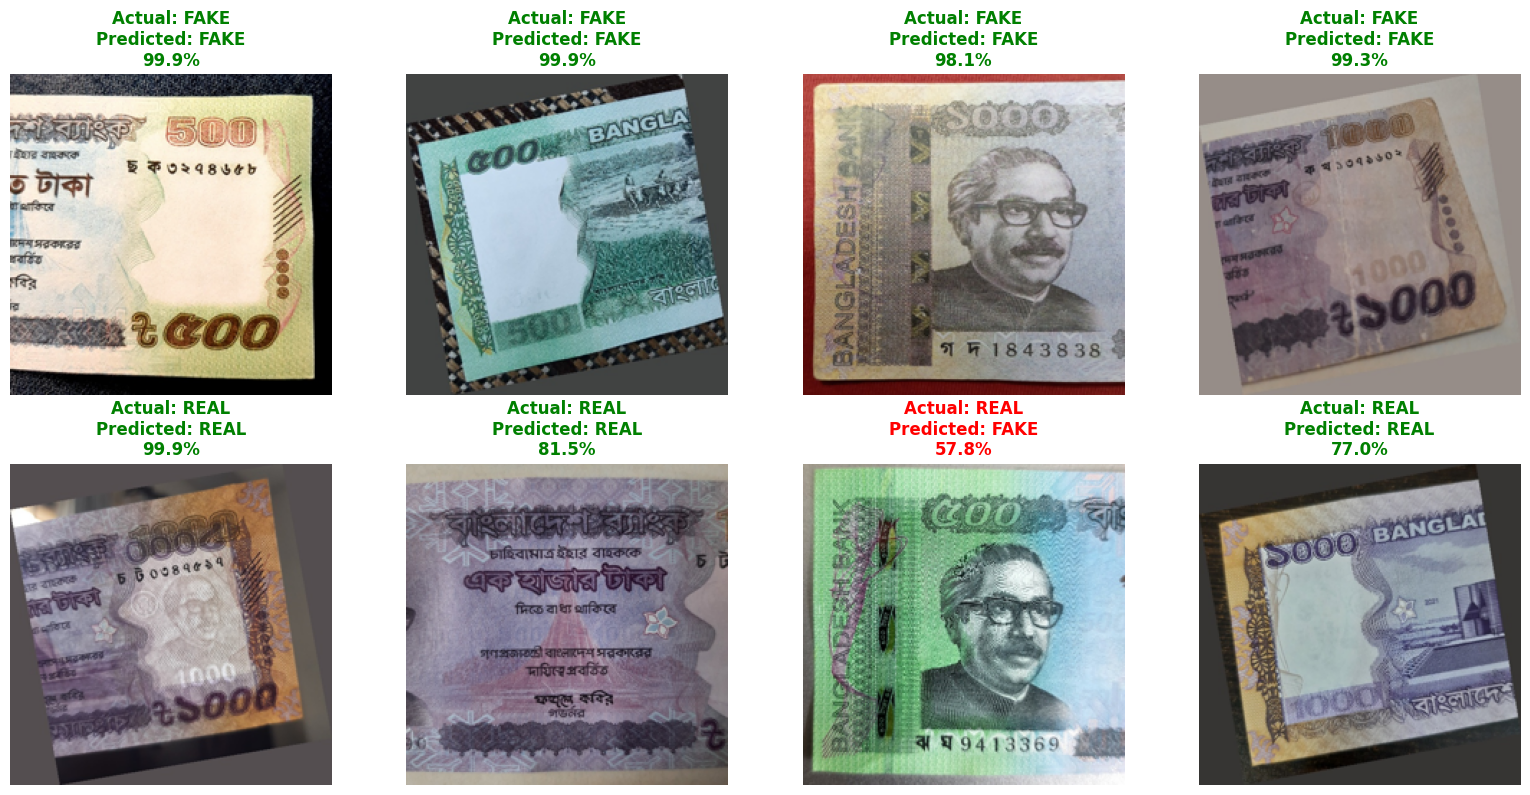

In [21]:
import random

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for class_name, row in [("fake", 0), ("real", 1)]:
    class_dir = os.path.join(TEST_DIR, class_name)
    images = random.sample(os.listdir(class_dir), 4)
    
    for col, img_name in enumerate(images):
        img_path = os.path.join(class_dir, img_name)
        result, confidence, img = predict_single_image(img_path)
        
        axes[row, col].imshow(img)
        color = 'green' if result == class_name.upper() else 'red'
        axes[row, col].set_title(f"Actual: {class_name.upper()}\nPredicted: {result}\n{confidence:.1f}%", 
                                 color=color, fontweight='bold')
        axes[row, col].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "prediction_samples.png"), dpi=150)
plt.show()

Found 1668 images belonging to 2 classes.
Generating predictions for test set...


C:\Users\mdsha\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 358ms/step

Total samples: 1668
Predictions shape: (1668, 1)


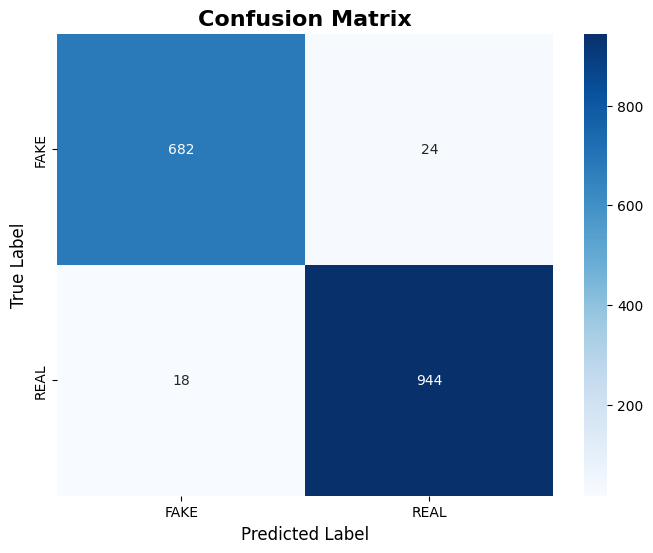


Confusion Matrix:
[[682  24]
 [ 18 944]]


In [22]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

print("Generating predictions for test set...")
predictions = model.predict(test_generator, verbose=1)
predicted_classes = (predictions > 0.5).astype(int).flatten()
true_classes = test_generator.classes

print(f"\nTotal samples: {len(true_classes)}")
print(f"Predictions shape: {predictions.shape}")

# Cell 6: Confusion Matrix
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['FAKE', 'REAL'],
            yticklabels=['FAKE', 'REAL'])
plt.title('Confusion Matrix', fontsize=16, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.savefig(os.path.join(PROJECT_DIR, "confusion_matrix.png"), dpi=150, bbox_inches='tight')
plt.show()

print("\nConfusion Matrix:")
print(cm)


In [23]:
print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
report = classification_report(true_classes, predicted_classes, 
                               target_names=['FAKE', 'REAL'],
                               digits=4)
print(report)

# Save report
with open(os.path.join(PROJECT_DIR, "classification_report.txt"), 'w') as f:
    f.write(report)



CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE     0.9743    0.9660    0.9701       706
        REAL     0.9752    0.9813    0.9782       962

    accuracy                         0.9748      1668
   macro avg     0.9747    0.9736    0.9742      1668
weighted avg     0.9748    0.9748    0.9748      1668



In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

accuracy = accuracy_score(true_classes, predicted_classes)
precision = precision_score(true_classes, predicted_classes)
recall = recall_score(true_classes, predicted_classes)
f1 = f1_score(true_classes, predicted_classes)
auc = roc_auc_score(true_classes, predictions)

print("\n" + "="*60)
print("PERFORMANCE METRICS")
print("="*60)
print(f"Accuracy:  {accuracy*100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"AUC Score: {auc:.4f}")



PERFORMANCE METRICS
Accuracy:  97.48%
Precision: 0.9752
Recall:    0.9813
F1 Score:  0.9782
AUC Score: 0.9923


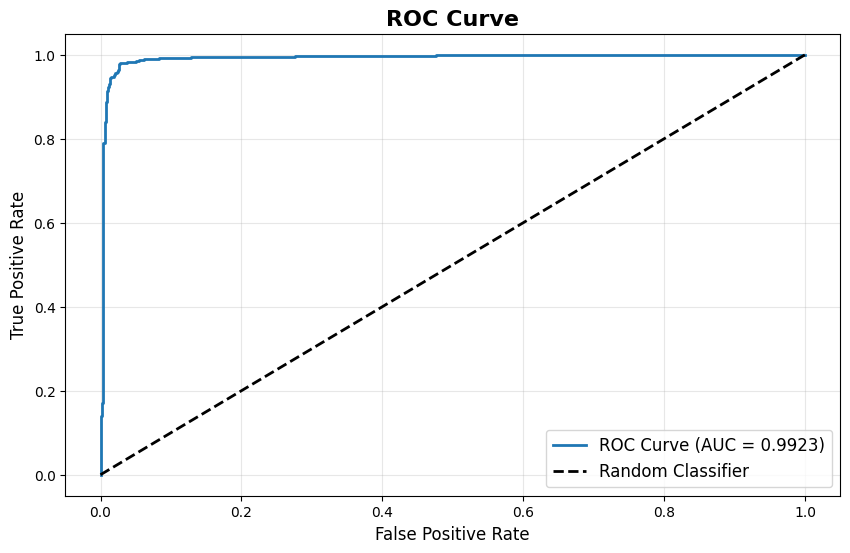


Model evaluation complete!


In [25]:
fpr, tpr, thresholds = roc_curve(true_classes, predictions)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'ROC Curve (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve', fontsize=16, fontweight='bold')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(PROJECT_DIR, "roc_curve.png"), dpi=150, bbox_inches='tight')
plt.show()

print("\nModel evaluation complete!")